# 🍃EcoVolt⚡
---
###Integrantes e responsabilidades:

**1 e 2 - Pesquisa e coleta de dados:**
Mateus Tarcisio, Breno Neves e Rafael Brito

**3 - Tratamento dos dados e cálculos:**
Mateus Tarcisio

**4 - Visualização e gráficos:**
Pedro Pereira

**5 - Dashborde e interface:**
Lucas Oliveira

**6 - Relatório,validação e documentação:**
Matheus Alexandre





---


# **1.0 Estado atual comprovado**

#### **O que existe e onde posso verificar:**

A EcoVolt possui uma proposta de solução voltada ao desenvolvimento de um software B2B para organizar informações de baterias usadas e apoiar decisões sobre seu próximo destino. A equipe já desenvolveu pesquisas sobre SOH (State of Health), CDE e passaporte de baterias, além de discutir a viabilidade técnica e comercial da solução. As evidências devem ser verificadas no relatório situacional, nos materiais de pesquisa, nas apresentações da equipe e nos registros de desenvolvimento disponíveis. A implementação funcional de cada componente deve ser comprovada por meio do código, do protótipo ou de demonstrações reproduzíveis.
 [Portfolio](https://www.google.com/url?q=https%3A%2F%2Fsites.google.com%2Fcesar.school%2Fbd2026-1%2Finicio)

####**O que ainda é hipótese, proposta ou dependência:**

A coleta automatizada de dados de fabricantes e BMS, o cálculo confiável de SOH a partir de dados reais, a implementação do CDE, a geração de recomendações de destino e a construção de um passaporte digital integrado ainda precisam ter seu estágio de execução verificado. A validação comercial também depende de entrevistas com potenciais clientes e, idealmente, de um piloto com baterias e dados reais. O acesso a informações proprietárias de fabricantes permanece uma dependência caso a solução exija dados que não estejam publicamente disponíveis.

####**Mudanças em relação ao SR1 e justificativa:**

Após o SR1, a equipe ampliou a visão inicial, que estava mais concentrada no descarte de baterias de veículos elétricos e na criação de um passaporte digital. A partir das discussões com o monitor, passou a priorizar a inteligência de dados necessária para avaliar baterias usadas e orientar seu próximo destino. A mudança ocorreu porque depender de fabricantes para obter históricos completos e dados de BMS poderia dificultar a viabilidade do MVP. Assim, a proposta passou a considerar o uso de informações já disponíveis, documentos e diagnósticos acessíveis, permitindo construir uma solução progressiva e reduzir dependências externas. Essa alteração deve ser registrada como uma evolução posterior ao SR1.

####**Versão de escopo adotada nesta AV1:**

Desenvolver e validar um MVP B2B da EcoVolt para cadastro e organização de informações de baterias usadas, registro das evidências disponíveis e apoio à avaliação de seu próximo destino. A proposta contempla a estruturação progressiva do passaporte digital, o uso do SOH como indicador de condição da bateria e a aplicação de um CDE para apoiar a triagem entre possibilidades como segunda vida, reparo, avaliação adicional ou reciclagem. O escopo inicial prioriza dados acessíveis e critérios documentados, sem depender de integração direta com fabricantes. A implementação e a validação técnica de cada funcionalidade serão apresentadas conforme as evidências efetivamente disponíveis.



### Implementação demonstrável (CRUD)

In [2]:

"""
⚡ EV Fleet Manager — Gestão de frota de veículos elétricos
Uso: python3 ev_fleet.py
"""

import json
import os
import platform
import sys
from datetime import datetime
from pathlib import Path

# ══════════════════════════════════════════════════════════════
#  CORES & UI
# ══════════════════════════════════════════════════════════════

RESET    = "\033[0m"
NEGRITO  = "\033[1m"
VERDE    = "\033[92m"
AZUL     = "\033[94m"
CIANO    = "\033[96m"
AMARELO  = "\033[93m"
VERMELHO = "\033[91m"

def cor(texto, codigo):
    return f"{codigo}{texto}{RESET}"

def limpar_tela():
    os.system("cls" if platform.system() == "Windows" else "clear")

def separador():
    print(cor("  " + "─" * 56, "\033[90m"))

def cabecalho(titulo):
    print()
    print(cor("  " + "═" * 56, CIANO))
    print(cor("  ⚡ EV FLEET MANAGER", VERDE) + "  " + cor(f"│  {titulo}", AMARELO))
    print(cor("  " + "═" * 56, CIANO))

def menu_principal():
    print()
    print(cor("  " + "▓" * 56, CIANO))
    print()
    print(cor("        ⚡  EV FLEET MANAGER", VERDE + NEGRITO))
    print(cor("        Gestão inteligente de frotas elétricas", "\033[90m"))
    print()
    print(cor("  " + "▓" * 56, CIANO))
    print()

def gerar_barra(pct, largura=20):
    cheio = int(pct / 100 * largura)
    vazio = largura - cheio
    cor_b = VERDE if pct >= 80 else (AMARELO if pct >= 60 else VERMELHO)
    return cor("█" * cheio, cor_b) + cor("░" * vazio, "\033[90m") + RESET

# ══════════════════════════════════════════════════════════════
#  PERSISTÊNCIA
# ══════════════════════════════════════════════════════════════

ARQUIVO_DADOS = Path.home() / ".ev_fleet" / "frota.json"

def carregar_frota():
    ARQUIVO_DADOS.parent.mkdir(parents=True, exist_ok=True)
    if ARQUIVO_DADOS.exists():
        try:
            return json.loads(ARQUIVO_DADOS.read_text(encoding="utf-8"))
        except Exception:
            return []
    return []

def salvar_frota(frota):
    ARQUIVO_DADOS.parent.mkdir(parents=True, exist_ok=True)
    ARQUIVO_DADOS.write_text(json.dumps(frota, ensure_ascii=False, indent=2), encoding="utf-8")

# ══════════════════════════════════════════════════════════════
#  MOTOR DE DIAGNÓSTICO
# ══════════════════════════════════════════════════════════════

_DEG_ANUAL_BASE  = {1: 1.5,  2: 2.5,  3: 4.0}
_FATOR_FREQ_CARGA= {1: 0.85, 2: 1.00, 3: 1.20, 4: 1.45}
_FATOR_TIPO_CARGA= {1: 0.90, 2: 1.00, 3: 1.15, 4: 1.35}
_AJUSTE_PERCEPCAO= {1: -0.5, 2: +1.5, 3: +4.0}
SOH_FIM_VIDA     = 0.70

_FREQ_USO_LABEL   = {1: "Pouco uso",        2: "Uso moderado",      3: "Uso intenso"}
_FREQ_CARGA_LABEL = {1: "Raramente",         2: "Moderado",          3: "Diariamente",     4: "Várias vezes/dia"}
_TIPO_CARGA_LABEL = {1: "Lento (AC)",        2: "Semi-rápido (AC)",  3: "Rápido (DC 50kW)","4": "Ultra-rápido (DC)"}
_PERCEPCAO_LABEL  = {1: "Mesma de sempre",   2: "Diminuiu um pouco", 3: "Diminuiu muito"}
_TIPO_USO_LABEL   = {1: "Urbano",            2: "Rodoviário",        3: "Misto"}
_INTENCAO_LABEL   = {1: "Continuar usando",  2: "Vender o veículo",
                     3: "Energia solar / 2ª vida",                    4: "Reciclar / descartar"}

def calcular_diagnostico(dados):
    anos       = dados["anos_uso"]
    freq_uso   = dados["freq_uso"]
    freq_carga = dados["freq_carga"]
    tipo_carga = dados["tipo_carga"]
    percepcao  = dados["percepcao"]
    aut_orig   = dados["autonomia_original"]
    aut_hoje   = dados["autonomia_hoje"]
    intencao   = dados["intencao"]

    deg_anual    = _DEG_ANUAL_BASE[freq_uso] * _FATOR_FREQ_CARGA[freq_carga] * _FATOR_TIPO_CARGA[tipo_carga]
    deg_acum     = min(deg_anual * anos + _AJUSTE_PERCEPCAO[percepcao], 40)
    deg_real     = (1 - aut_hoje / aut_orig) * 100 if aut_orig > 0 else 0
    deg_final    = deg_acum * 0.60 + deg_real * 0.40
    soh          = max(0.0, 1.0 - deg_final / 100)
    saude_pct    = soh * 100
    aut_estimada = aut_orig * soh

    anos_ate_fim = max(0.0, (soh - SOH_FIM_VIDA) * 100 / deg_anual) if deg_anual > 0 else 15.0
    if anos_ate_fim >= 1:
        vida_label = f"≈ {anos_ate_fim:.1f} anos"
    elif anos_ate_fim > 0:
        vida_label = f"≈ {int(anos_ate_fim*12)} meses"
    else:
        vida_label = "Fim de vida útil atingido"

    km_dia       = {1: 20, 2: 55, 3: 100}[freq_uso]
    km_restantes = max(0, anos_ate_fim * 365 * km_dia)

    if saude_pct >= 90:   soh_label = "Excelente (≥ 90%)"
    elif saude_pct >= 80: soh_label = "Boa (80–89%)"
    elif saude_pct >= 70: soh_label = "Regular (70–79%)"
    elif saude_pct >= 60: soh_label = "Degradada (60–69%)"
    else:                 soh_label = "Crítica (< 60%)"

    if deg_final <= 10:   deg_label = "Mínima — dentro do esperado"
    elif deg_final <= 20: deg_label = "Moderada — normal para o uso"
    elif deg_final <= 30: deg_label = "Elevada — atenção recomendada"
    else:                 deg_label = "Severa — avaliação presencial indicada"

    # Recomendações
    recs = []
    if saude_pct >= 85:
        recs.append("Bateria em ótimo estado — continue com as boas práticas.")
    elif saude_pct >= 70:
        recs.append("Bateria em estado razoável — monitoramento semestral recomendado.")
    else:
        recs.append("Bateria com degradação significativa — avalie revisão técnica.")
    if tipo_carga >= 3 and freq_carga >= 3:
        recs.append("Reduza carregamentos rápidos frequentes para preservar as células.")
    if tipo_carga <= 2:
        recs.append("Ótima prática: carregamento lento preserva a bateria a longo prazo.")
    if deg_anual > 3:
        recs.append("Taxa de degradação acima da média — considere ajustar hábitos de carga.")
    recs.append({
        1: "Mantenha a carga entre 20% e 80% sempre que possível.",
        2: "Diagnóstico técnico certificado aumenta o valor de revenda.",
        3: "Bateria degradada ainda tem boa performance em energia solar.",
        4: "Procure pontos de reciclagem certificados para descarte correto.",
    }[intencao])

    return {
        "saude_pct":          round(saude_pct, 1),
        "soh_label":          soh_label,
        "degradacao_pct":     round(deg_final, 1),
        "degradacao_label":   deg_label,
        "autonomia_estimada": aut_estimada,
        "vida_util_anos":     vida_label,
        "anos_ate_fim":       round(anos_ate_fim, 1),
        "km_restantes":       km_restantes,
        "recomendacoes":      recs,
        "intencao_label":     _INTENCAO_LABEL[intencao],
        "freq_uso_label":     _FREQ_USO_LABEL[freq_uso],
        "freq_carga_label":   _FREQ_CARGA_LABEL[freq_carga],
        "tipo_carga_label":   _TIPO_CARGA_LABEL.get(tipo_carga, str(tipo_carga)),
        "percepcao_label":    _PERCEPCAO_LABEL[percepcao],
        "tipo_uso_label":     _TIPO_USO_LABEL[dados["tipo_uso"]],
    }

# ══════════════════════════════════════════════════════════════
#  HELPERS DE INPUT
# ══════════════════════════════════════════════════════════════

def entrada_float(prompt, minimo=0, maximo=9999):
    while True:
        try:
            v = float(input(prompt))
            if minimo <= v <= maximo:
                return v
            print(cor(f"  ⚠  Digite um valor entre {minimo} e {maximo}.", AMARELO))
        except ValueError:
            print(cor("  ⚠  Digite um número válido.", AMARELO))

def entrada_int(prompt, minimo=0, maximo=9999):
    while True:
        try:
            v = int(input(prompt))
            if minimo <= v <= maximo:
                return v
            print(cor(f"  ⚠  Digite um valor entre {minimo} e {maximo}.", AMARELO))
        except ValueError:
            print(cor("  ⚠  Digite um número inteiro válido.", AMARELO))

def escolha_menu(opcoes):
    for k, v in opcoes.items():
        print(f"  {cor(f'[{k}]', CIANO)} {v}")
    while True:
        resp = input(cor("\n  ➤ Sua escolha: ", AZUL)).strip()
        if resp in opcoes:
            return resp
        print(cor("  ⚠  Opção inválida.", AMARELO))

# ══════════════════════════════════════════════════════════════
#  FLUXO DE AVALIAÇÃO (5 partes)
# ══════════════════════════════════════════════════════════════

def parte1():
    print(cor("\n  ┌─ PARTE 1 — Autonomia & Tempo de Uso ─────────────────┐", CIANO))
    aut_orig  = entrada_float(cor("  │  Autonomia original do veículo (km): ", RESET), 50, 1500)
    aut_hoje  = entrada_float(cor("  │  Autonomia percebida hoje (km): ", RESET), 10, 1500)
    anos_uso  = entrada_float(cor("  │  Há quantos anos usa este veículo? ", RESET), 0, 30)
    print(cor("  └───────────────────────────────────────────────────────┘", CIANO))
    return dict(autonomia_original=aut_orig, autonomia_hoje=aut_hoje, anos_uso=anos_uso)

def parte2():
    print(cor("\n  ┌─ PARTE 2 — Frequência & Tipo de Uso ─────────────────┐", CIANO))
    print(cor("\n  Frequência de uso do veículo:", NEGRITO))
    fu = escolha_menu({"1": "Pouco uso  (< 30 km/dia)",
                       "2": "Uso moderado (30–80 km/dia)",
                       "3": "Uso intenso (> 80 km/dia)"})
    print(cor("\n  Com que frequência você carrega?", NEGRITO))
    fc = escolha_menu({"1": "Raramente (< 2×/semana)",
                       "2": "Moderado (2–5×/semana)",
                       "3": "Diariamente",
                       "4": "Várias vezes ao dia"})
    print(cor("\n  Tipo de carregamento predominante:", NEGRITO))
    tc = escolha_menu({"1": "Lento (AC doméstico / 3,7 kW)",
                       "2": "Semi-rápido (AC 7–22 kW)",
                       "3": "Rápido (DC 50 kW)",
                       "4": "Ultra-rápido (DC > 100 kW)"})
    print(cor("  └───────────────────────────────────────────────────────┘", CIANO))
    return dict(freq_uso=int(fu), freq_carga=int(fc), tipo_carga=int(tc))

def parte3():
    print(cor("\n  ┌─ PARTE 3 — Percepção de Autonomia ───────────────────┐", CIANO))
    print(cor("\n  Como você se sente em relação à autonomia atual\n"
              "  comparada ao início?", NEGRITO))
    p = escolha_menu({
        "1": "Continua da mesma forma — sem diferença percebida",
        "2": "Diminuiu um pouco — percebo perda leve",
        "3": "Diminuiu muito — perda significativa e constante"
    })
    print(cor("  └───────────────────────────────────────────────────────┘", CIANO))
    return dict(percepcao=int(p))

def parte4():
    print(cor("\n  ┌─ PARTE 4 — Identificação do Veículo ─────────────────┐", CIANO))
    marca  = input(cor("  │  Marca do veículo: ", RESET)).strip() or "Não informado"
    modelo = input(cor("  │  Modelo: ", RESET)).strip() or "Não informado"
    ano    = entrada_int(cor("  │  Ano do veículo: ", RESET), 2000, datetime.now().year + 1)
    regiao = input(cor("  │  Região / Cidade: ", RESET)).strip() or "Não informado"
    print(cor("\n  Tipo de uso predominante:", NEGRITO))
    tu = escolha_menu({"1": "Urbano (paradas frequentes, baixa velocidade)",
                       "2": "Rodoviário (estradas, velocidade constante)",
                       "3": "Misto"})
    print(cor("\n  O que pretende fazer com a bateria?", NEGRITO))
    it = escolha_menu({
        "1": "Continuar usando normalmente",
        "2": "Vender o veículo em breve",
        "3": "Instalar energia solar / segunda vida da bateria",
        "4": "Reciclar / descartar corretamente"
    })
    print(cor("  └───────────────────────────────────────────────────────┘", CIANO))
    return dict(marca=marca, modelo=modelo, ano=ano, regiao=regiao,
                tipo_uso=int(tu), intencao=int(it))

def exibir_diagnostico(dados, diag):
    cor_s = VERDE if diag["saude_pct"] >= 80 else (AMARELO if diag["saude_pct"] >= 60 else VERMELHO)
    barra = gerar_barra(diag["saude_pct"])
    print(f"\n  {NEGRITO}Veículo:{RESET} {dados.get('marca','')} {dados.get('modelo','')} ({dados.get('ano','')})")
    print(f"  {NEGRITO}Região:{RESET}  {dados.get('regiao','')}")
    separador()
    saude_str = f"{diag['saude_pct']:.1f}%"
    print(f"  {NEGRITO}Saúde da Bateria:{RESET}  {cor(saude_str, cor_s)}  {barra}")
    print(f"  {NEGRITO}SOH (State of Health):{RESET}  {cor(diag['soh_label'], cor_s)}")
    print(f"\n  {NEGRITO}Degradação estimada:{RESET}  {diag['degradacao_pct']:.1f}%  — {diag['degradacao_label']}")
    print(f"  {NEGRITO}Autonomia real estimada:{RESET}  {diag['autonomia_estimada']:.0f} km")
    print(f"  {NEGRITO}Vida útil restante:{RESET}  {cor(diag['vida_util_anos'], CIANO)}")
    print(f"  {NEGRITO}Km restantes estimados:{RESET}  {diag['km_restantes']:,.0f} km")
    print(f"\n  {NEGRITO}Recomendações:{RESET}")
    for linha in diag["recomendacoes"]:
        print(f"    {cor('•', VERDE)} {linha}")
    print(f"\n  {NEGRITO}Intenção declarada:{RESET}  {diag['intencao_label']}")
    separador()

def nova_avaliacao(veiculo_existente=None):
    limpar_tela()
    cabecalho("AVALIAÇÃO DO VEÍCULO ELÉTRICO")
    dados = {**parte1(), **parte2(), **parte3(), **parte4(),
             "data_avaliacao": datetime.now().strftime("%Y-%m-%d %H:%M")}

    if veiculo_existente:
        dados["id"] = veiculo_existente["id"]
        historico   = veiculo_existente.get("historico", [])
        historico.append({k: v for k, v in veiculo_existente.items()
                          if k not in ("id", "historico")})
        dados["historico"] = historico
    else:
        frota    = carregar_frota()
        dados["id"]      = max((v["id"] for v in frota), default=0) + 1
        dados["historico"] = []

    dados["diagnostico"] = calcular_diagnostico(dados)

    limpar_tela()
    cabecalho("DIAGNÓSTICO DA BATERIA")
    exibir_diagnostico(dados, dados["diagnostico"])
    input(cor("\n  Pressione ENTER para continuar...", AMARELO))
    return dados

# ══════════════════════════════════════════════════════════════
#  RELATÓRIO EM TEXTO
# ══════════════════════════════════════════════════════════════

def gerar_relatorio_texto(frota):
    agora = datetime.now().strftime("%d/%m/%Y %H:%M")
    L = []
    L.append("=" * 62)
    L.append("  EV FLEET MANAGER — RELATÓRIO DA FROTA")
    L.append(f"  Gerado em: {agora}")
    L.append("=" * 62)
    L.append(f"\n  Total de veículos : {len(frota)}")
    L.append(f"  Saudáveis (≥ 80%) : {sum(1 for v in frota if v.get('diagnostico',{}).get('saude_pct',0)>=80)}")
    L.append(f"  Atenção  (60–79%) : {sum(1 for v in frota if 60<=v.get('diagnostico',{}).get('saude_pct',0)<80)}")
    L.append(f"  Críticos  (< 60%) : {sum(1 for v in frota if v.get('diagnostico',{}).get('saude_pct',100)<60)}")
    for v in frota:
        d = v.get("diagnostico", {})
        L.append("\n" + "─" * 62)
        L.append(f"  ID #{v['id']}  |  {v.get('marca','')} {v.get('modelo','')}  ({v.get('ano','')})")
        L.append(f"  Região: {v.get('regiao','')}  |  Avaliado em: {v.get('data_avaliacao','')}")
        L.append(f"\n  Autonomia original : {v.get('autonomia_original','')} km")
        L.append(f"  Autonomia hoje     : {v.get('autonomia_hoje','')} km")
        L.append(f"  Anos de uso        : {v.get('anos_uso','')} anos")
        L.append(f"  Frequência de uso  : {d.get('freq_uso_label','')}")
        L.append(f"  Frequência de carga: {d.get('freq_carga_label','')}")
        L.append(f"  Tipo de carregador : {d.get('tipo_carga_label','')}")
        L.append(f"  Percepção do dono  : {d.get('percepcao_label','')}")
        L.append(f"  Tipo de uso        : {d.get('tipo_uso_label','')}")
        L.append(f"\n  ── DIAGNÓSTICO ──────────────────────────────────")
        L.append(f"  Saúde da bateria   : {d.get('saude_pct',0):.1f}%  ({d.get('soh_label','')})")
        L.append(f"  Degradação estimada: {d.get('degradacao_pct',0):.1f}%  — {d.get('degradacao_label','')}")
        L.append(f"  Autonomia estimada : {d.get('autonomia_estimada',0):.0f} km")
        L.append(f"  Vida útil restante : {d.get('vida_util_anos','')}")
        L.append(f"  Km restantes est.  : {d.get('km_restantes',0):,.0f} km")
        L.append(f"  Intenção do dono   : {d.get('intencao_label','')}")
        L.append("\n  RECOMENDAÇÕES:")
        for rec in d.get("recomendacoes", []):
            L.append(f"    • {rec}")
    L.append("\n" + "=" * 62)
    L.append("  Fim do relatório")
    L.append("=" * 62)
    return "\n".join(L)

# ══════════════════════════════════════════════════════════════
#  GESTÃO DA FROTA
# ══════════════════════════════════════════════════════════════

def listar_frota(frota):
    limpar_tela()
    cabecalho("FROTA CADASTRADA")
    if not frota:
        print(cor("  Nenhum veículo cadastrado ainda.", AMARELO))
        input(cor("\n  Pressione ENTER...", AMARELO)); return
    print(f"\n  {'ID':<5} {'Marca/Modelo':<28} {'Ano':<6} {'Saúde':<10} Avaliação")
    separador()
    for v in frota:
        d     = v.get("diagnostico", {})
        saude = d.get("saude_pct", 0)
        cor_s = VERDE if saude >= 80 else (AMARELO if saude >= 60 else VERMELHO)
        print(f"  {cor(str(v['id']), CIANO):<14} "
              f"{v.get('marca','?')+' '+v.get('modelo',''):<28} "
              f"{v.get('ano',''):<6} "
              f"{cor(f'{saude:.0f}%', cor_s):<19} "
              f"{v.get('data_avaliacao','—')}")
    separador()
    input(cor("\n  Pressione ENTER...", AMARELO))

def ver_veiculo(frota):
    limpar_tela(); cabecalho("DETALHES DO VEÍCULO")
    if not frota:
        print(cor("  Nenhum veículo cadastrado.", AMARELO))
        input(cor("\n  Pressione ENTER...", AMARELO)); return
    id_str  = input(cor("  ID do veículo: ", AZUL)).strip()
    veiculo = next((v for v in frota if str(v["id"]) == id_str), None)
    if not veiculo:
        print(cor("  Veículo não encontrado.", VERMELHO))
        input(cor("\n  Pressione ENTER...", AMARELO)); return
    exibir_diagnostico(veiculo, veiculo.get("diagnostico", {}))
    input(cor("\n  Pressione ENTER...", AMARELO))

def remover_veiculo(frota):
    limpar_tela(); cabecalho("REMOVER VEÍCULO")
    id_str  = input(cor("  ID do veículo a remover: ", AZUL)).strip()
    veiculo = next((v for v in frota if str(v["id"]) == id_str), None)
    if not veiculo:
        print(cor("  Veículo não encontrado.", VERMELHO))
        input(cor("\n  Pressione ENTER...", AMARELO)); return frota
    conf = input(cor(f"  Confirma remoção de {veiculo['marca']} {veiculo['modelo']}? (s/N): ", AMARELO)).strip().lower()
    if conf == "s":
        frota = [v for v in frota if str(v["id"]) != id_str]
        salvar_frota(frota)
        print(cor("  ✓ Veículo removido.", VERDE))
    else:
        print(cor("  Operação cancelada.", AMARELO))
    input(cor("\n  Pressione ENTER...", AMARELO))
    return frota

def gerar_relatorio_frota(frota):
    limpar_tela(); cabecalho("RELATÓRIO DA FROTA")
    if not frota:
        print(cor("  Nenhum veículo na frota.", AMARELO))
        input(cor("\n  Pressione ENTER...", AMARELO)); return
    txt  = gerar_relatorio_texto(frota)
    nome = f"relatorio_frota_{datetime.now().strftime('%Y%m%d_%H%M%S')}.txt"
    path = ARQUIVO_DADOS.parent / nome
    path.write_text(txt, encoding="utf-8")
    print(txt)
    print(cor(f"\n  ✓ Relatório salvo em: {path}", VERDE))
    input(cor("\n  Pressione ENTER...", AMARELO))

# ══════════════════════════════════════════════════════════════
#  MENUS
# ══════════════════════════════════════════════════════════════

def menu_gestao():
    while True:
        frota = carregar_frota()
        limpar_tela(); cabecalho("GESTÃO DA FROTA")
        print(f"\n  {NEGRITO}Veículos cadastrados:{RESET} {cor(str(len(frota)), CIANO)}\n")
        opcao = escolha_menu({
            "1": "Adicionar novo veículo",
            "2": "Fazer nova avaliação (veículo existente)",
            "3": "Visualizar todos os veículos",
            "4": "Detalhes de um veículo",
            "5": "Remover veículo",
            "6": "Gerar relatório da frota",
            "0": "Voltar"
        })
        if opcao == "1":
            dados = nova_avaliacao()
            frota.append(dados); salvar_frota(frota)
            print(cor(f"\n  ✓ Veículo #{dados['id']} adicionado!", VERDE))
            input(cor("  Pressione ENTER...", AMARELO))
        elif opcao == "2":
            if not frota:
                print(cor("\n  Nenhum veículo cadastrado.", AMARELO))
                input(cor("  Pressione ENTER...", AMARELO)); continue
            for v in frota:
                print(f"  {cor(str(v['id']), CIANO)}  {v.get('marca','?')} {v.get('modelo','')}")
            id_str  = input(cor("  ID para reavaliação: ", AZUL)).strip()
            veiculo = next((v for v in frota if str(v["id"]) == id_str), None)
            if not veiculo:
                print(cor("  Não encontrado.", VERMELHO))
                input(cor("  Pressione ENTER...", AMARELO)); continue
            atualizado = nova_avaliacao(veiculo)
            frota = [atualizado if str(v["id"]) == id_str else v for v in frota]
            salvar_frota(frota)
            print(cor("  ✓ Avaliação atualizada.", VERDE))
            input(cor("  Pressione ENTER...", AMARELO))
        elif opcao == "3": listar_frota(frota)
        elif opcao == "4": ver_veiculo(frota)
        elif opcao == "5": frota = remover_veiculo(frota)
        elif opcao == "6": gerar_relatorio_frota(frota)
        elif opcao == "0": break

def main():
    while True:
        limpar_tela(); menu_principal()
        opcao = escolha_menu({
            "1": "Iniciar avaliação de veículo",
            "2": "Gestão da frota",
            "0": "Sair"
        })
        if opcao == "1":
            dados = nova_avaliacao()
            frota = carregar_frota()
            frota.append(dados); salvar_frota(frota)
            print(cor(f"\n  ✓ Veículo #{dados['id']} salvo na frota!", VERDE))
            input(cor("  Pressione ENTER...", AMARELO))
        elif opcao == "2":
            menu_gestao()
        elif opcao == "0":
            limpar_tela()
            print(cor("\n  Até logo! ⚡\n", VERDE))
            sys.exit(0)

if __name__ == "__main__":
    main()



  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓

        ⚡  EV FLEET MANAGER
        Gestão inteligente de frotas elétricas

  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓

  [1] Iniciar avaliação de veículo
  [2] Gestão da frota
  [0] Sair

  ➤ Sua escolha: 0

  Até logo! ⚡



SystemExit: 0

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)




---


# **2.0 Decisão,perguntas e datasets**


---


###**ABVE Data -**
Apoiar o planejamento de mercado e a identificação de regiões que merecem investigação. Não mede diretamente a quantidade de baterias usadas disponíveis. Serve para a pessoa que exerce a função de analista de mercado consulta o painel mensalmente para decidir quais estados devem ser priorizados na prospecção de parceiros e oportunidades, no contexto da expansão dos veículos eletrificados no Brasil.
### P01 -
Como evoluem os emplacamentos de veículos eletrificados no Brasil ao longo do tempo e quais unidades da Federação apresentam maior crescimento e participação nesse mercado?
### Ação apoiada -
Identificar estados com expansão do mercado eletrificado e priorizar regiões para investigar oportunidades futuras.
### Fonte candidata (dataset) -
ABVE Data — Emplacamentos mensais de veículos eletrificados no Brasil. [LINK DO DATASET](https://recarregados.com/dados/emplacamentos-eletricos-hibridos)

---

### **CALCE Battery -**
Investigar a viabilidade de estimar a saúde da bateria com dados experimentais acessíveis. Serve para a pessoa que exerce a função de analista de dados consulta o painel a cada análise de bateria para avaliar padrões de degradação e verificar a viabilidade da estimativa de SOH, no contexto do desenvolvimento do motor analítico da EcoVolt.
### P02 -
É possível estimar o SOH de uma bateria usando dados de ciclos e capacidade, sem depender de informações proprietárias dos fabricantes?
### Ação apoiada
Desenvolver e testar um método de estimativa de SOH para o MVP.
### Fonte candidata (dataset)
CALCE Battery Dataset — University of Maryland.[LINK DO DATASET](https://github.com/RanitDas21/CALCE_CS2_Battery_SOH_ML/blob/main/CALCE_CS2_ML_SOH_Dataset.csv)

---
### **Second-life LFP Battery**
Apoiar a definição inicial das variáveis do motor de decisão. Os resultados não certificam segurança nem determinam sozinhos o destino da bateria. Serve para a pessoa que exerce a função de responsável pela triagem consulta o painel a cada bateria avaliada para identificar quais precisam de testes adicionais antes de uma possível reutilização, no contexto da gestão de baterias usadas.
### P03 -

Quais características mensuráveis ajudam a diferenciar baterias usadas e a identificar quais precisam de avaliação técnica adicional antes de uma possível aplicação de segunda vida?
### Ação apoiada
Definir variáveis e critérios preliminares para apoiar a triagem de baterias no CDE.

### Fonte candidata (dataset)
Second-life LFP Battery Dataset — Zenodo.
[LINK DO DATASET](https://zenodo.org/records/18630889?utm_source=chatgpt.com&preview_file=SLBs_LFP_charging_data.zip)


---


**O que fica fora desta entrega:** a integração direta com sistemas BMS e fabricantes, a certificação técnica das baterias, a validação de segurança para reutilização e a definição automática do destino final de cada bateria. Também ficam fora a comprovação da disponibilidade de baterias usadas no mercado brasileiro e a validação comercial da solução com clientes reais.

**Conclusão que ainda não podemos sustentar:** não podemos afirmar que o modelo desenvolvido consegue determinar com segurança quais baterias estão aptas para uma segunda vida, nem que a solução reduz custos ou impactos ambientais na prática. As análises permitem investigar padrões e desenvolver critérios preliminares, mas essas conclusões dependem de validação com dados reais, testes técnicos e pilotos com potenciais clientes.

Resumo:

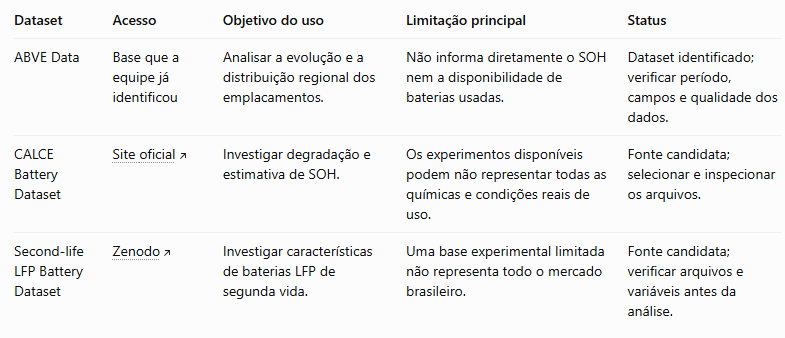

In [3]:
import pandas as pd

emplacamento_de_carros = pd.read_csv("/content/recarregados-emplacamentos-eletricos-hibridos.csv")
calculo_do_SOH = pd.read_csv("/content/CALCE_CS2_ML_SOH_Dataset.csv")
capacidade_da_bateria = pd.read_excel("5.596Ah_charge.xlsx")

FileNotFoundError: [Errno 2] No such file or directory: '/content/recarregados-emplacamentos-eletricos-hibridos.csv'